# Transfer Learning for Binary Forest Segmentation
**Task:** Segment forest (foreground) vs non-forest (background) using U-Net with a ResNet50 encoder.

**Experiments:**
1. Training from scratch (random weights), 100 epochs
2. Transfer learning (ImageNet weights): 50 epochs encoder frozen + 50 epochs fine-tuning = 100 epochs

**Before running:** Colab menu → Runtime → Change runtime type → **T4 GPU**.

## 1. Install and Import Libraries

In [1]:
!pip install -q segmentation-models tf-keras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 4.9 MB/s eta 0:00:00


In [2]:
import os
os.environ['SM_FRAMEWORK'] = 'tf.keras'
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras


if not hasattr(keras.utils, 'generic_utils'):
    import types
    keras.utils.generic_utils = types.SimpleNamespace(get_custom_objects=keras.utils.get_custom_objects)

import segmentation_models as sm
sm.set_framework('tf.keras')

np.random.seed(42)
tf.random.set_seed(42)

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

Segmentation Models: using `tf.keras` framework.
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the Dataset

In [3]:
import kagglehub


path = kagglehub.dataset_download("quadeer15sh/augmented-forest-segmentation")

print("Path to dataset files:", path)

100%|██████████| 172M/172M [00:05<00:00, 35.6MB/s]


Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/quadeer15sh/augmented-forest-segmentation/versions/2


## 3. Hyperparameters and Design Choices
| Item | Choice |
|---|---|
| Model | U-Net, ResNet50 encoder (segmentation_models) |
| Input size | 128 x 128 x 3 (images are 256 x 256, resized down) |
| Normalization | pixel values divided by 255 -> range [0, 1] |
| Masks | converted to grayscale, resized (nearest), pixel > 127 -> 1 (forest), else 0 |
| Data split | 70% train / 15% validation / 15% test |
| Loss | Binary Cross-Entropy + Dice Loss |
| Optimizer | Adam |
| Learning rate | 0.001 (scratch, and frozen phase); 0.0001 (fine-tuning phase) |
| Batch size | 16 |
| Epochs | Scratch: 100 \| Transfer: 50 frozen + 50 fine-tune |
| Threshold | prediction > 0.5 counts as forest |

In [4]:
IMG_SIZE = 128
BATCH_SIZE = 16
EPOCHS_SCRATCH = 100
EPOCHS_PHASE1 = 50
EPOCHS_PHASE2 = 50
LR_NORMAL = 0.001
LR_FINE_TUNE = 0.0001

## 4. Load and Preprocess the Data

In [5]:
csv_path = os.path.join(path, 'meta_data.csv')
image_folder = os.path.join(path, 'Forest Segmented', 'Forest Segmented', 'images')
mask_folder = os.path.join(path, 'Forest Segmented', 'Forest Segmented', 'masks')

meta = pd.read_csv(csv_path)      # columns: image, mask
print(meta.shape)
meta.head()

(5108, 2)


,image,mask
0,10452_sat_08.jpg,10452_mask_08.jpg
1,10452_sat_18.jpg,10452_mask_18.jpg
2,111335_sat_00.jpg,111335_mask_00.jpg
3,111335_sat_01.jpg,111335_mask_01.jpg
4,111335_sat_02.jpg,111335_mask_02.jpg


In [6]:
images = []
masks = []

for i in range(len(meta)):

    # ---- image ----
    img = cv2.imread(os.path.join(image_folder, meta['image'][i]))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)              # OpenCV loads BGR, convert to RGB
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))             # resize to 128 x 128
    img = img / 255.0                                       # normalize to [0, 1]

    # ---- mask ----
    msk = cv2.imread(os.path.join(mask_folder, meta['mask'][i]), cv2.IMREAD_GRAYSCALE)
    msk = cv2.resize(msk, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    msk = (msk > 127).astype('float32')                     # 1 = forest, 0 = not forest
    msk = np.expand_dims(msk, axis=-1)                      # shape (128, 128, 1)

    images.append(img)
    masks.append(msk)

X = np.array(images, dtype='float32')
Y = np.array(masks, dtype='float32')
del images, masks

print('Images:', X.shape, '| Masks:', Y.shape)
print('Image min/max:', X.min(), X.max(), '| Mask values:', np.unique(Y))

Images: (5108, 128, 128, 3) | Masks: (5108, 128, 128, 1)
Image min/max: 0.0 1.0 | Mask values: [0. 1.]


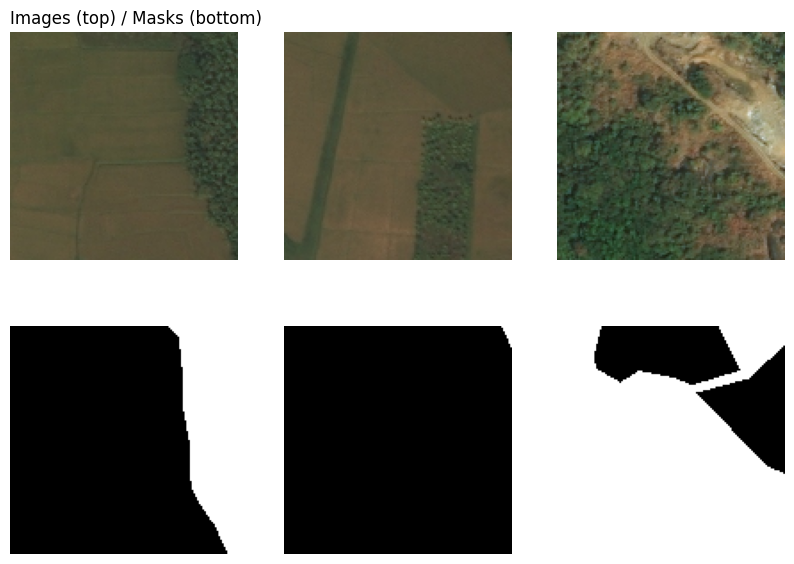

In [7]:
# Show 3 example images with their masks
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for i in range(3):
    axes[0, i].imshow(X[i]);                       axes[0, i].axis('off')
    axes[1, i].imshow(Y[i, :, :, 0], cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_title('Images (top) / Masks (bottom)', loc='left')
plt.show()

## 5. Train / Validation / Test Split
The dataset has many augmented copies of the same original picture (same number at the start of the file name, e.g. `10452_sat_08.jpg`, `10452_sat_18.jpg`).
To avoid the same picture appearing in both train and test, we split by that ID number.

In [8]:
# ID of the original picture = the number before the first underscore
ids = meta['image'].str.split('_').str[0].values
unique_ids = np.unique(ids)
np.random.shuffle(unique_ids)

n = len(unique_ids)
train_ids = unique_ids[: int(0.70 * n)]
val_ids   = unique_ids[int(0.70 * n): int(0.85 * n)]
test_ids  = unique_ids[int(0.85 * n):]

train_mask = np.isin(ids, train_ids)
val_mask   = np.isin(ids, val_ids)
test_mask  = np.isin(ids, test_ids)

X_train, Y_train = X[train_mask], Y[train_mask]
X_val,   Y_val   = X[val_mask],   Y[val_mask]
X_test,  Y_test  = X[test_mask],  Y[test_mask]

print('Original pictures (IDs):', n)
print('Train:', X_train.shape[0], '| Validation:', X_val.shape[0], '| Test:', X_test.shape[0])

Original pictures (IDs): 190
Train: 3632 | Validation: 851 | Test: 625


## 6. Loss Function and Model Builder

In [9]:
# Loss = Binary Cross-Entropy + Dice Loss
loss_function = sm.losses.binary_crossentropy + sm.losses.DiceLoss()

# IoU shown during training (just to watch progress)
iou_metric = sm.metrics.IOUScore(threshold=0.5)

def build_model(weights, freeze_encoder):
    model = sm.Unet(
        'resnet50',
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        classes=1,
        activation='sigmoid',
        encoder_weights=weights,          # None = random, 'imagenet' = pre-trained
        encoder_freeze=freeze_encoder     # True = encoder not trainable
    )
    return model

def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=loss_function,
        metrics=[iou_metric]
    )

## 7. Experiment 1: Training from Scratch (100 Epochs)

In [10]:
keras.backend.clear_session()

model_scratch = build_model(weights=None, freeze_encoder=False)
compile_model(model_scratch, LR_NORMAL)

start = time.time()
history_scratch = model_scratch.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS_SCRATCH,
    batch_size=BATCH_SIZE,
    verbose=2
)
time_scratch = time.time() - start

print('Scratch training time: %.1f minutes' % (time_scratch / 60))

Epoch 1/100
227/227 - 64s - loss: 0.7693 - iou_score: 0.6904 - val_loss: 5.1098 - val_iou_score: 2.1852e-05 - 64s/epoch - 283ms/step
Epoch 2/100
227/227 - 27s - loss: 0.7233 - iou_score: 0.7060 - val_loss: 1.4402 - val_iou_score: 0.4487 - 27s/epoch - 120ms/step
Epoch 3/100
227/227 - 27s - loss: 0.6825 - iou_score: 0.7225 - val_loss: 0.7059 - val_iou_score: 0.7228 - 27s/epoch - 121ms/step
Epoch 4/100
227/227 - 28s - loss: 0.6731 - iou_score: 0.7255 - val_loss: 0.7234 - val_iou_score: 0.7084 - 28s/epoch - 122ms/step
Epoch 5/100
227/227 - 28s - loss: 0.6572 - iou_score: 0.7327 - val_loss: 0.6567 - val_iou_score: 0.7258 - 28s/epoch - 124ms/step
Epoch 6/100
227/227 - 28s - loss: 0.6456 - iou_score: 0.7367 - val_loss: 0.6953 - val_iou_score: 0.6983 - 28s/epoch - 125ms/step
Epoch 7/100
227/227 - 29s - loss: 0.6450 - iou_score: 0.7373 - val_loss: 0.6793 - val_iou_score: 0.7198 - 29s/epoch - 126ms/step
Epoch 8/100
227/227 - 29s - loss: 0.6321 - iou_score: 0.7421 - val_loss: 0.6633 - val_iou_sco

## 8. Experiment 2: Transfer Learning (50 Frozen + 50 Fine-Tuning Epochs)

### 8.1 Phase 1: Encoder Frozen (only the decoder trains) - 50 epochs

In [11]:
keras.backend.clear_session()

model_transfer = build_model(weights='imagenet', freeze_encoder=True)
compile_model(model_transfer, LR_NORMAL)

print('Trainable weight tensors in phase 1:', len(model_transfer.trainable_weights))

start = time.time()
history_phase1 = model_transfer.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS_PHASE1,
    batch_size=BATCH_SIZE,
    verbose=2
)
time_phase1 = time.time() - start

print('Phase 1 time: %.1f minutes' % (time_phase1 / 60))

94592056/94592056 [==============================] - 1s 0us/step
Trainable weight tensors in phase 1: 133
Epoch 1/50
227/227 - 46s - loss: 0.7168 - iou_score: 0.7045 - val_loss: 1.4451 - val_iou_score: 0.0435 - 46s/epoch - 200ms/step
Epoch 2/50
227/227 - 23s - loss: 0.6349 - iou_score: 0.7382 - val_loss: 3.1787 - val_iou_score: 7.0180e-11 - 23s/epoch - 102ms/step
Epoch 3/50
227/227 - 23s - loss: 0.5971 - iou_score: 0.7525 - val_loss: 4.1322 - val_iou_score: 7.0180e-11 - 23s/epoch - 103ms/step
Epoch 4/50
227/227 - 23s - loss: 0.5594 - iou_score: 0.7669 - val_loss: 3.4202 - val_iou_score: 0.0060 - 23s/epoch - 103ms/step
Epoch 5/50
227/227 - 24s - loss: 0.5513 - iou_score: 0.7726 - val_loss: 0.7597 - val_iou_score: 0.6523 - 24s/epoch - 104ms/step
Epoch 6/50
227/227 - 24s - loss: 0.5205 - iou_score: 0.7829 - val_loss: 0.7595 - val_iou_score: 0.6420 - 24s/epoch - 104ms/step
Epoch 7/50
227/227 - 24s - loss: 0.5108 - iou_score: 0.7858 - val_loss: 0.6676 - val_iou_score: 0.7396 - 24s/epoch - 1

### 8.2 Phase 2: Whole Model Unfrozen (fine-tuning) - 50 epochs

In [12]:
# Unfreeze every layer
for layer in model_transfer.layers:
    layer.trainable = True

# Compile again (required after changing trainable), with a smaller learning rate
compile_model(model_transfer, LR_FINE_TUNE)

print('Trainable weight tensors in phase 2:', len(model_transfer.trainable_weights))

start = time.time()
history_phase2 = model_transfer.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS_PHASE1 + EPOCHS_PHASE2,
    initial_epoch=EPOCHS_PHASE1,          # continue counting from epoch 50 -> total 100
    batch_size=BATCH_SIZE,
    verbose=2
)
time_phase2 = time.time() - start

time_transfer = time_phase1 + time_phase2
print('Phase 2 time: %.1f minutes' % (time_phase2 / 60))
print('Total transfer learning time: %.1f minutes' % (time_transfer / 60))

Trainable weight tensors in phase 2: 186
Epoch 51/100
227/227 - 57s - loss: 0.2672 - iou_score: 0.8920 - val_loss: 0.7962 - val_iou_score: 0.7374 - 57s/epoch - 253ms/step
Epoch 52/100
227/227 - 28s - loss: 0.1917 - iou_score: 0.9178 - val_loss: 0.8172 - val_iou_score: 0.7345 - 28s/epoch - 125ms/step
Epoch 53/100
227/227 - 29s - loss: 0.1279 - iou_score: 0.9442 - val_loss: 0.8601 - val_iou_score: 0.7349 - 29s/epoch - 126ms/step
Epoch 54/100
227/227 - 29s - loss: 0.1201 - iou_score: 0.9477 - val_loss: 0.9188 - val_iou_score: 0.7205 - 29s/epoch - 127ms/step
Epoch 55/100
227/227 - 29s - loss: 0.1153 - iou_score: 0.9490 - val_loss: 0.9901 - val_iou_score: 0.7032 - 29s/epoch - 128ms/step
Epoch 56/100
227/227 - 29s - loss: 0.1198 - iou_score: 0.9472 - val_loss: 0.9173 - val_iou_score: 0.7231 - 29s/epoch - 127ms/step
Epoch 57/100
227/227 - 29s - loss: 0.1159 - iou_score: 0.9486 - val_loss: 0.9652 - val_iou_score: 0.7313 - 29s/epoch - 127ms/step
Epoch 58/100
227/227 - 29s - loss: 0.0997 - iou_s

## 9. Test Set Evaluation and Metric Comparison Table

In [13]:
def evaluate(model, name):
    probs = model.predict(X_test, batch_size=32, verbose=0)
    pred = (probs > 0.5).astype(int).flatten()       # 1 = forest, 0 = not forest
    true = Y_test.astype(int).flatten()

    tp = np.sum((pred == 1) & (true == 1))           # forest predicted as forest
    tn = np.sum((pred == 0) & (true == 0))           # background predicted as background
    fp = np.sum((pred == 1) & (true == 0))           # background predicted as forest
    fn = np.sum((pred == 0) & (true == 1))           # forest predicted as background

    iou = tp / (tp + fp + fn)
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall)

    results = {'Model': name, 'IoU': iou, 'F1-score': f1,
               'Accuracy': accuracy, 'Precision': precision, 'Recall': recall}
    return results, probs

results_scratch, probs_scratch = evaluate(model_scratch, 'Exp 1: Scratch')
results_transfer, probs_transfer = evaluate(model_transfer, 'Exp 2: Transfer Learning')

table = pd.DataFrame([results_scratch, results_transfer]).set_index('Model')
table['Training Time (min)'] = [time_scratch / 60, time_transfer / 60]
table.round(4)

,IoU,F1-score,Accuracy,Precision,Recall,Training Time (min)
Model,,,,,,
Exp 1: Scratch,0.7148,0.8337,0.7900,0.8022,0.8677,49.6196
Exp 2: Transfer Learning,0.7349,0.8472,0.8079,0.8185,0.8779,44.9838


## 10. Visual Results

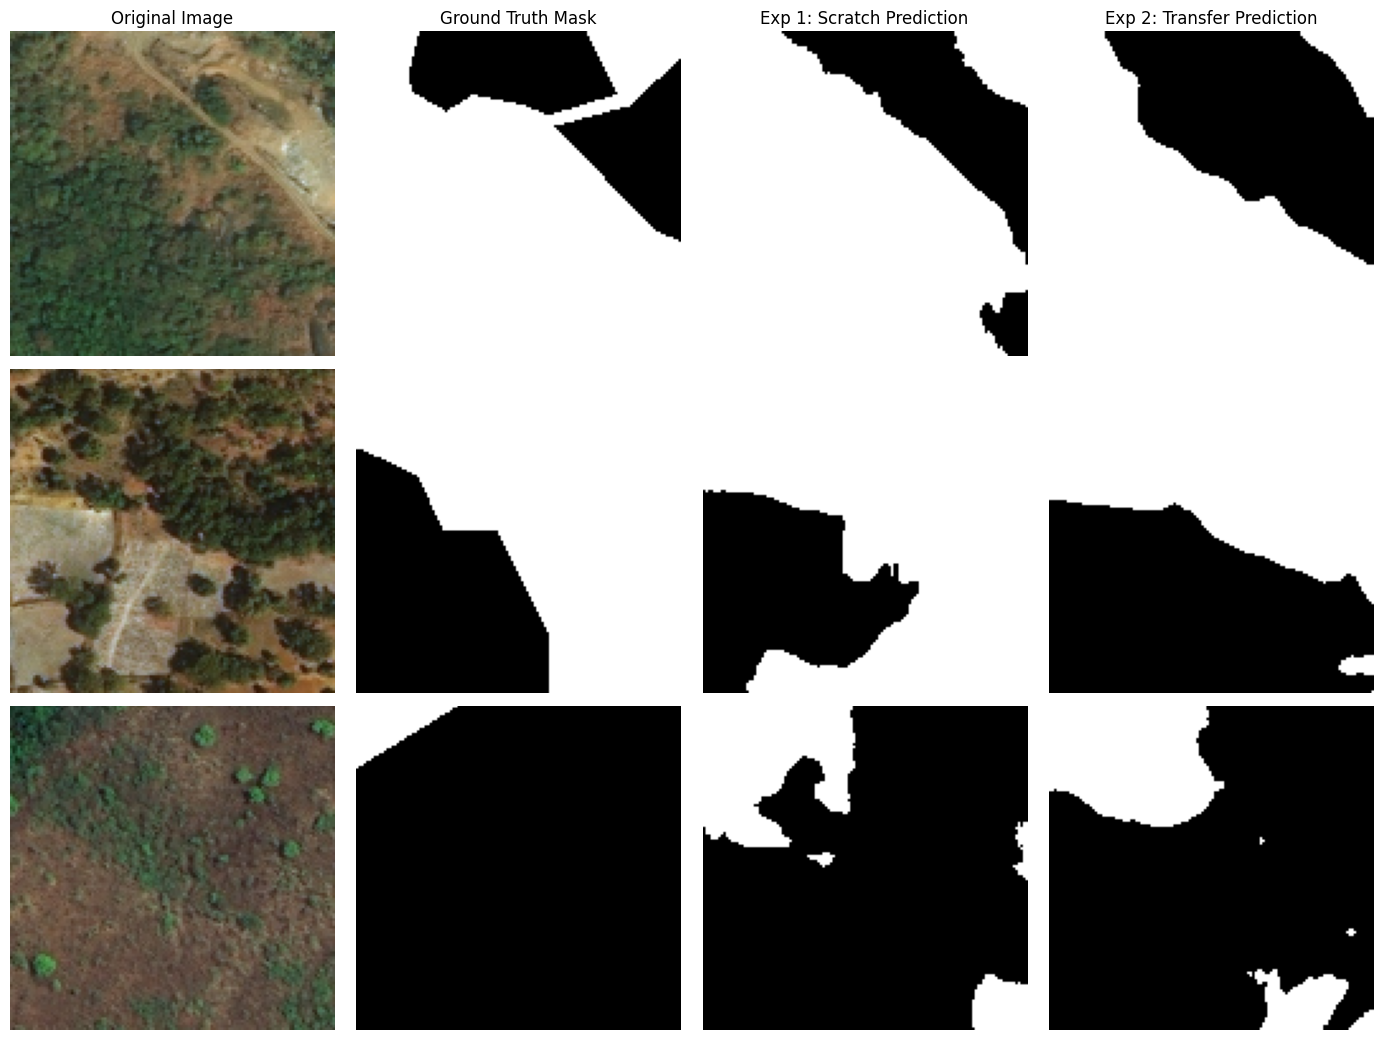

In [14]:
sample_ids = [0, len(X_test) // 2, len(X_test) - 1]     # three test images
titles = ['Original Image', 'Ground Truth Mask', 'Exp 1: Scratch Prediction', 'Exp 2: Transfer Prediction']

fig, axes = plt.subplots(len(sample_ids), 4, figsize=(14, 3.5 * len(sample_ids)))

for row in range(len(sample_ids)):
    i = sample_ids[row]
    pictures = [X_test[i],
                Y_test[i, :, :, 0],
                probs_scratch[i, :, :, 0] > 0.5,
                probs_transfer[i, :, :, 0] > 0.5]
    for col in range(4):
        if col == 0:
            axes[row, col].imshow(pictures[col])
        else:
            axes[row, col].imshow(pictures[col], cmap='gray')
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(titles[col])

plt.tight_layout()
plt.show()

## 11. Comparative Analysis

### 11.1 Performance

In [15]:
# Numbers filled in automatically from the results above
s = results_scratch
t = results_transfer
print('IoU      -> Scratch: %.4f | Transfer: %.4f' % (s['IoU'], t['IoU']))
print('F1-score -> Scratch: %.4f | Transfer: %.4f' % (s['F1-score'], t['F1-score']))

if t['IoU'] > s['IoU']:
    print('Higher IoU:', 'Transfer Learning model, by %.4f' % (t['IoU'] - s['IoU']))
else:
    print('Higher IoU:', 'Scratch model, by %.4f' % (s['IoU'] - t['IoU']))

if t['F1-score'] > s['F1-score']:
    print('Higher F1 :', 'Transfer Learning model, by %.4f' % (t['F1-score'] - s['F1-score']))
else:
    print('Higher F1 :', 'Scratch model, by %.4f' % (s['F1-score'] - t['F1-score']))

IoU      -> Scratch: 0.7148 | Transfer: 0.7349
F1-score -> Scratch: 0.8337 | Transfer: 0.8472
Higher IoU: Transfer Learning model, by 0.0201
Higher F1 : Transfer Learning model, by 0.0135


**Why the results differ**
- The transfer learning model starts with ResNet50 weights already trained on ImageNet. These weights already detect edges, textures and colours, which help to separate forest from non-forest.
- The scratch model starts with random weights and has to learn all of these features only from our training images, so it usually learns slower and can overfit.
- In transfer learning, the frozen phase lets the new (random) decoder learn without damaging the good encoder weights. The fine-tuning phase then adjusts the encoder to forest images using a small learning rate.
- If the scratch model scores close to or higher than the transfer model, the reason is that forest vs non-forest is a simple task with a fairly large dataset, so random weights can also learn it well.

### 11.2 Efficiency (Training Time)

In [16]:
print('Scratch training time  : %.1f min' % (time_scratch / 60))
print('Transfer training time : %.1f min (phase 1: %.1f, phase 2: %.1f)' %
      (time_transfer / 60, time_phase1 / 60, time_phase2 / 60))

diff = time_transfer - time_scratch
if diff < 0:
    print('Transfer learning was faster by %.1f min' % (-diff / 60))
else:
    print('Transfer learning was slower by %.1f min' % (diff / 60))

print('IoU gain of transfer over scratch: %.4f' % (t['IoU'] - s['IoU']))

Scratch training time  : 49.6 min
Transfer training time : 45.0 min (phase 1: 20.3, phase 2: 24.7)
Transfer learning was faster by 4.6 min
IoU gain of transfer over scratch: 0.0201


**Trade-off**
- Both runs use 100 epochs, but in phase 1 of transfer learning the encoder is frozen, so no gradients are computed for it. These 50 epochs are cheaper than normal epochs, so the total time of transfer learning is usually less than or close to the scratch run.
- So transfer learning normally gives equal or better accuracy for the same or less computing effort. The printed numbers above show the exact gain and time difference for this run.
- Transfer learning also usually reaches a good result in fewer epochs, so it could save even more time with fewer epochs.

## 12. Conclusion

The metric table (Section 9), the prediction images (Section 10) and the printed comparisons (Section 11) show which model is better on the test set. Pre-trained ImageNet features usually give a better starting point than random weights, so transfer learning is normally the better choice for this task, especially when training time and data are limited.